# 07 Beta Diversity - Method Comparison

## Contents

- [Distance Matrix Calculation and PCoA](#distance-pcoa)
  - [Whole ASVs](#whole-asvs)
  - [8-mers](#8-mers)
  - [16-mers](#16-mers)
  - [Uncolored PCoA Comparison Grid](#uncolored-grid)
- [Exploratory PCoA by Sample Metadata](#metadata-pcoa)
  - [Settlement Type](#settlement-type)
  - [Diet](#diet)
  - [Age](#age)
  - [Sex](#sex)
- [Summary and Workflow Selection](#summary)

## 1 - Distance Matrix Calculation and PCoA

In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from qiime2 import Artifact
from qiime2 import Metadata
from seaborn import scatterplot
from skbio import DistanceMatrix, OrdinationResults

%matplotlib inline

In [20]:
in_dir = Path("../data/processed_ignored")
out_dir = in_dir / "07_beta_diversity"
vis_dir = Path("../data/processed/07_beta_diversity")

asv_table = in_dir / "06_diversity/core_metrics/rarefied_table.qza"
rep_seqs  = in_dir / "03_taxonomy/rep_set_fungi_filtered.qza"
metadata  = in_dir / "06_diversity/Final_metadata_with_GHSL.tsv"

out_dir.mkdir(parents=True, exist_ok=True)
vis_dir.mkdir(parents=True, exist_ok=True)

### 1.1 - Whole ASVs

#### Whole ASVs — Bray–Curtis distance and PCoA

Use the fungal ASV table from notebook 06, rarefied to 16,000 reads per sample. Calculate pairwise Bray–Curtis dissimilarities across all 150 samples using their ASV counts. A value of 0 means two samples have identical ASV counts, and a value of 1 means they share no detected ASVs. Save the distance matrix for the PCoA.<br>
Run principal coordinates analysis (PCoA) on the Bray–Curtis distance matrix. Save the sample coordinates and the proportion of variation explained by each axis for the 3 × 3 comparison grid.

In [3]:
asv_bray_dm = out_dir / "asv_bray_curtis_distance.qza"
asv_bray_pcoa = out_dir / "asv_bray_curtis_pcoa.qza"

!qiime diversity beta \
    --i-table "{asv_table}" \
    --p-metric braycurtis \
    --o-distance-matrix "{asv_bray_dm}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/asv_bray_curtis_distance.qza


In [4]:
!qiime diversity pcoa \
    --i-distance-matrix "{asv_bray_dm}" \
    --o-pcoa "{asv_bray_pcoa}"

Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/asv_bray_curtis_pcoa.qza


#### Whole ASVs — Jaccard distance and PCoA

Use the same rarefied ASV table to compare which ASVs are detected in each pair of samples. Jaccard uses presence and absence. A distance of 0 means the two samples contain the same set of ASVs, and a distance of 1 means they share no detected ASVs.<br>
Run PCoA on the whole-ASV Jaccard distance matrix. Save the sample coordinates and the proportion of variation explained by each axis for the 3 × 3 comparison grid.

In [5]:
asv_jaccard_dm = out_dir / "asv_jaccard_distance.qza"
asv_jaccard_pcoa = out_dir / "asv_jaccard_pcoa.qza"

!qiime diversity beta \
    --i-table "{asv_table}" \
    --p-metric jaccard \
    --o-distance-matrix "{asv_jaccard_dm}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/asv_jaccard_distance.qza


In [6]:
!qiime diversity pcoa \
    --i-distance-matrix "{asv_jaccard_dm}" \
    --o-pcoa "{asv_jaccard_pcoa}"

Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/asv_jaccard_pcoa.qza


#### Whole ASVs — Aitchison distance and PCoA

Use the same rarefied ASV table to compare samples based on log-ratios between ASV counts. Add a pseudocount of 1 to every count so that the log-ratios are defined when an ASV has a zero count. Use the same pseudocount for the 8-mer and 16-mer tables.<br>
Run PCoA on the whole-ASV Aitchison distance matrix. Save the sample coordinates and the proportion of variation explained by each axis for the 3 × 3 comparison grid

In [7]:
aitchison_pseudocount = 1
asv_aitchison_dm = out_dir / "asv_aitchison_distance.qza"
asv_aitchison_pcoa = out_dir / "asv_aitchison_pcoa.qza"

!qiime diversity beta \
    --i-table "{asv_table}" \
    --p-metric aitchison \
    --p-pseudocount {aitchison_pseudocount} \
    --o-distance-matrix "{asv_aitchison_dm}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/asv_aitchison_distance.qza


In [8]:
!qiime diversity pcoa \
    --i-distance-matrix "{asv_aitchison_dm}" \
    --o-pcoa "{asv_aitchison_pcoa}"

Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/asv_aitchison_pcoa.qza


### 1.2 - 8-mers

#### Build the 8-mer feature table

Break the representative ITS1 sequences into overlapping 8-base windows. For each sample, weight the 8-mer counts from each ASV by its abundance in the rarefied ASV table. Save the resulting table for the three 8-mer distance calculations.

In [9]:
kmer8_table = out_dir / "kmer8_table.qza"

!qiime kmerizer seqs-to-kmers \
    --i-sequences "{rep_seqs}" \
    --i-table "{asv_table}" \
    --p-kmer-size 8 \
    --o-kmer-table "{kmer8_table}"

Saved FeatureTable[Frequency] to: ../data/processed_ignored/07_beta_diversity/kmer8_table.qza


#### 8-mers — Bray–Curtis distance and PCoA

Calculate pairwise Bray–Curtis dissimilarities from the 8-mer counts, then run PCoA on the resulting distance matrix. Save both artifacts for the comparison grid.

In [10]:
kmer8_bray_dm = out_dir / "kmer8_bray_curtis_distance.qza"
kmer8_bray_pcoa = out_dir / "kmer8_bray_curtis_pcoa.qza"

!qiime diversity beta \
    --i-table "{kmer8_table}" \
    --p-metric braycurtis \
    --o-distance-matrix "{kmer8_bray_dm}"

!qiime diversity pcoa \
    --i-distance-matrix "{kmer8_bray_dm}" \
    --o-pcoa "{kmer8_bray_pcoa}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/kmer8_bray_curtis_distance.qza
Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/kmer8_bray_curtis_pcoa.qza


#### 8-mers — Jaccard distance and PCoA

Calculate pairwise Jaccard distances based on which 8-mers are detected in each sample. Run PCoA on the resulting distance matrix and save both artifacts for the comparison grid.

In [11]:
kmer8_jaccard_dm = out_dir / "kmer8_jaccard_distance.qza"
kmer8_jaccard_pcoa = out_dir / "kmer8_jaccard_pcoa.qza"

!qiime diversity beta \
    --i-table "{kmer8_table}" \
    --p-metric jaccard \
    --o-distance-matrix "{kmer8_jaccard_dm}"

!qiime diversity pcoa \
    --i-distance-matrix "{kmer8_jaccard_dm}" \
    --o-pcoa "{kmer8_jaccard_pcoa}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/kmer8_jaccard_distance.qza
Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/kmer8_jaccard_pcoa.qza


#### 8-mers — Aitchison distance and PCoA

Calculate pairwise Aitchison distances from log-ratios of 8-mer counts. Use the same pseudocount of 1 as for whole ASVs so the log-ratios are defined for zero counts. Run PCoA on the resulting distance matrix and save both artifacts for the comparison grid.

In [12]:
kmer8_aitchison_dm = out_dir / "kmer8_aitchison_distance.qza"
kmer8_aitchison_pcoa = out_dir / "kmer8_aitchison_pcoa.qza"

!qiime diversity beta \
    --i-table "{kmer8_table}" \
    --p-metric aitchison \
    --p-pseudocount {aitchison_pseudocount} \
    --o-distance-matrix "{kmer8_aitchison_dm}"

!qiime diversity pcoa \
    --i-distance-matrix "{kmer8_aitchison_dm}" \
    --o-pcoa "{kmer8_aitchison_pcoa}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/kmer8_aitchison_distance.qza
Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/kmer8_aitchison_pcoa.qza


### 1.3 - 16-mers

#### Build the 16-mer feature table

Count overlapping 16-base windows in the representative ITS1 sequences. Weight each ASV’s 16-mer counts by its abundance in each sample, using the same rarefied ASV table as for the 8-mers. Save the resulting table for the three 16-mer distance calculations.

In [13]:
kmer16_table = out_dir / "kmer16_table.qza"

!qiime kmerizer seqs-to-kmers \
    --i-sequences "{rep_seqs}" \
    --i-table "{asv_table}" \
    --p-kmer-size 16 \
    --o-kmer-table "{kmer16_table}"

Saved FeatureTable[Frequency] to: ../data/processed_ignored/07_beta_diversity/kmer16_table.qza


#### 16-mers — Bray–Curtis distance and PCoA

Calculate pairwise Bray–Curtis dissimilarities using the 16-mer counts. Run PCoA on the resulting distance matrix and save both artifacts for the comparison grid.

In [14]:
kmer16_bray_dm = out_dir / "kmer16_bray_curtis_distance.qza"
kmer16_bray_pcoa = out_dir / "kmer16_bray_curtis_pcoa.qza"

!qiime diversity beta \
    --i-table "{kmer16_table}" \
    --p-metric braycurtis \
    --o-distance-matrix "{kmer16_bray_dm}"

!qiime diversity pcoa \
    --i-distance-matrix "{kmer16_bray_dm}" \
    --o-pcoa "{kmer16_bray_pcoa}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/kmer16_bray_curtis_distance.qza
Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/kmer16_bray_curtis_pcoa.qza


#### 16-mers — Jaccard distance and PCoA

Calculate pairwise Jaccard distances based on which 16-mers are detected in each sample. Run PCoA on the resulting distance matrix and save both artifacts for the comparison grid.

In [15]:
kmer16_jaccard_dm = out_dir / "kmer16_jaccard_distance.qza"
kmer16_jaccard_pcoa = out_dir / "kmer16_jaccard_pcoa.qza"

!qiime diversity beta \
    --i-table "{kmer16_table}" \
    --p-metric jaccard \
    --o-distance-matrix "{kmer16_jaccard_dm}"

!qiime diversity pcoa \
    --i-distance-matrix "{kmer16_jaccard_dm}" \
    --o-pcoa "{kmer16_jaccard_pcoa}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/kmer16_jaccard_distance.qza
Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/kmer16_jaccard_pcoa.qza


#### 16-mers — Aitchison distance and PCoA

Calculate pairwise Aitchison distances from log-ratios of 16-mer counts, using the same pseudocount of 1 as for whole ASVs and 8-mers. Run PCoA on the resulting distance matrix and save both artifacts for the comparison grid.

In [16]:
kmer16_aitchison_dm = out_dir / "kmer16_aitchison_distance.qza"
kmer16_aitchison_pcoa = out_dir / "kmer16_aitchison_pcoa.qza"

!qiime diversity beta \
    --i-table "{kmer16_table}" \
    --p-metric aitchison \
    --p-pseudocount {aitchison_pseudocount} \
    --o-distance-matrix "{kmer16_aitchison_dm}"

!qiime diversity pcoa \
    --i-distance-matrix "{kmer16_aitchison_dm}" \
    --o-pcoa "{kmer16_aitchison_pcoa}"

Saved DistanceMatrix to: ../data/processed_ignored/07_beta_diversity/kmer16_aitchison_distance.qza
Saved PCoAResults to: ../data/processed_ignored/07_beta_diversity/kmer16_aitchison_pcoa.qza


### Check sample IDs across all nine distance matrices

Verify that every distance matrix contains the same 150 sample IDs as the rarefied ASV table. This confirms that all nine panels compare the same samples.

In [17]:
expected_ids = set(Artifact.load(asv_table).view(pd.DataFrame).index)
assert len(expected_ids) == 150, f"Expected 150 samples, found {len(expected_ids)}"

distance_paths = [
    asv_bray_dm, asv_jaccard_dm, asv_aitchison_dm,
    kmer8_bray_dm, kmer8_jaccard_dm, kmer8_aitchison_dm,
    kmer16_bray_dm, kmer16_jaccard_dm, kmer16_aitchison_dm,
]

for path in distance_paths:
    sample_ids = set(Artifact.load(path).view(DistanceMatrix).ids)
    assert sample_ids == expected_ids, (
        f"{path.name}: {len(expected_ids - sample_ids)} missing, "
        f"{len(sample_ids - expected_ids)} unexpected"
    )

print("All nine distance matrices contain the same 150 samples.")

All nine distance matrices contain the same 150 samples.


### Compare the nine PCoAs

Plot whole ASVs, 8-mers, and 16-mers as rows, with Bray–Curtis, Jaccard, and Aitchison as columns. Each panel shows the same 150 samples **without metadata coloring**. Look for recurring patterns and samples that sit far apart from the rest. The axis percentages describe how much variation each axis captures within its ordination.

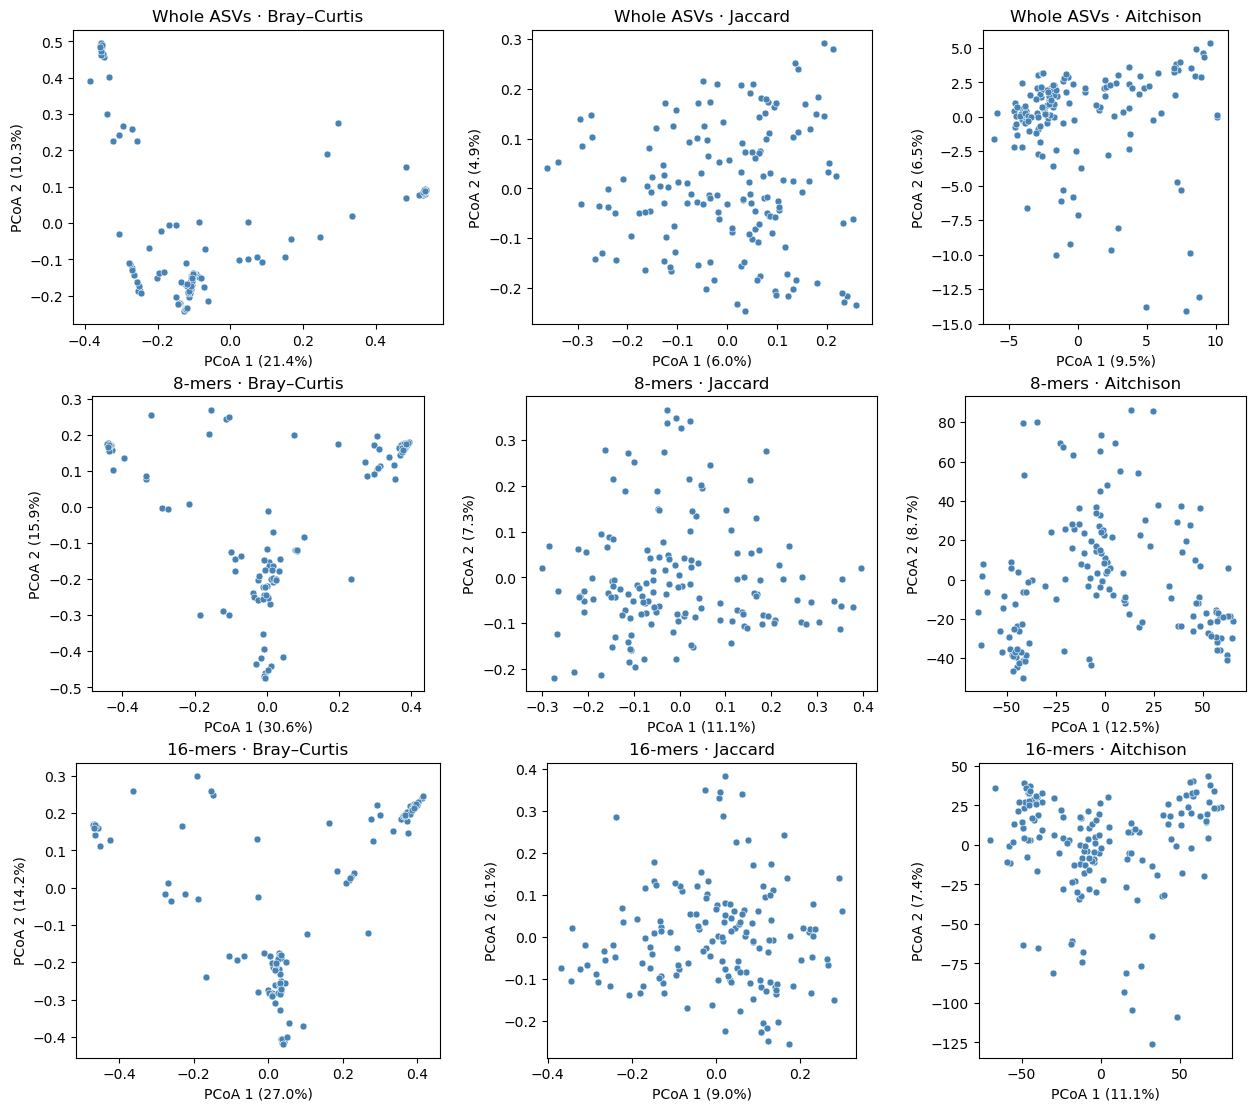

In [18]:
pcoa_paths = [
    [asv_bray_pcoa, asv_jaccard_pcoa, asv_aitchison_pcoa],
    [kmer8_bray_pcoa, kmer8_jaccard_pcoa, kmer8_aitchison_pcoa],
    [kmer16_bray_pcoa, kmer16_jaccard_pcoa, kmer16_aitchison_pcoa],
]

feature_labels = ["Whole ASVs", "8-mers", "16-mers"]
metric_labels = ["Bray–Curtis", "Jaccard", "Aitchison"]

fig, axes = plt.subplots(3, 3, figsize=(13, 11), layout="constrained")

for row, paths in enumerate(pcoa_paths):
    for col, path in enumerate(paths):
        ax = axes[row, col]
        ordination = Artifact.load(path).view(OrdinationResults)
        coords = ordination.samples
        explained = ordination.proportion_explained

        scatterplot(
            x=coords.iloc[:, 0],
            y=coords.iloc[:, 1],
            color="steelblue",
            s=25,
            ax=ax,
        )
        ax.set(
            title=f"{feature_labels[row]} · {metric_labels[col]}",
            xlabel=f"PCoA 1 ({explained.iloc[0]:.1%})",
            ylabel=f"PCoA 2 ({explained.iloc[1]:.1%})",
            aspect="equal",
        )

fig.savefig(vis_dir / "pcoa_comparison_uncolored.png", dpi=300)
plt.show()

### Inspect the available metadata columns

Load the cleaned metadata and list its columns and their data types. Use the list to choose a variable to display on the existing PCoAs.

In [21]:
metadata_df = Metadata.load(str(metadata)).to_dataframe()
display(metadata_df.dtypes.rename("Data type").to_frame())

,Data type
country_sample,object
state_sample,object
latitude_sample,float64
longitude_sample,float64
sex_sample,object
age_years_sample,float64
height_cm_sample,float64
weight_kg_sample,float64
bmi_sample,float64
diet_type_sample,object


## 2 - Exploratory PCoA by Sample Metadata

### 2.1 - Settlement type

Settlement_Type
Rural       65
Urban       56
Suburban    24
NaN          5
Name: count, dtype: int64

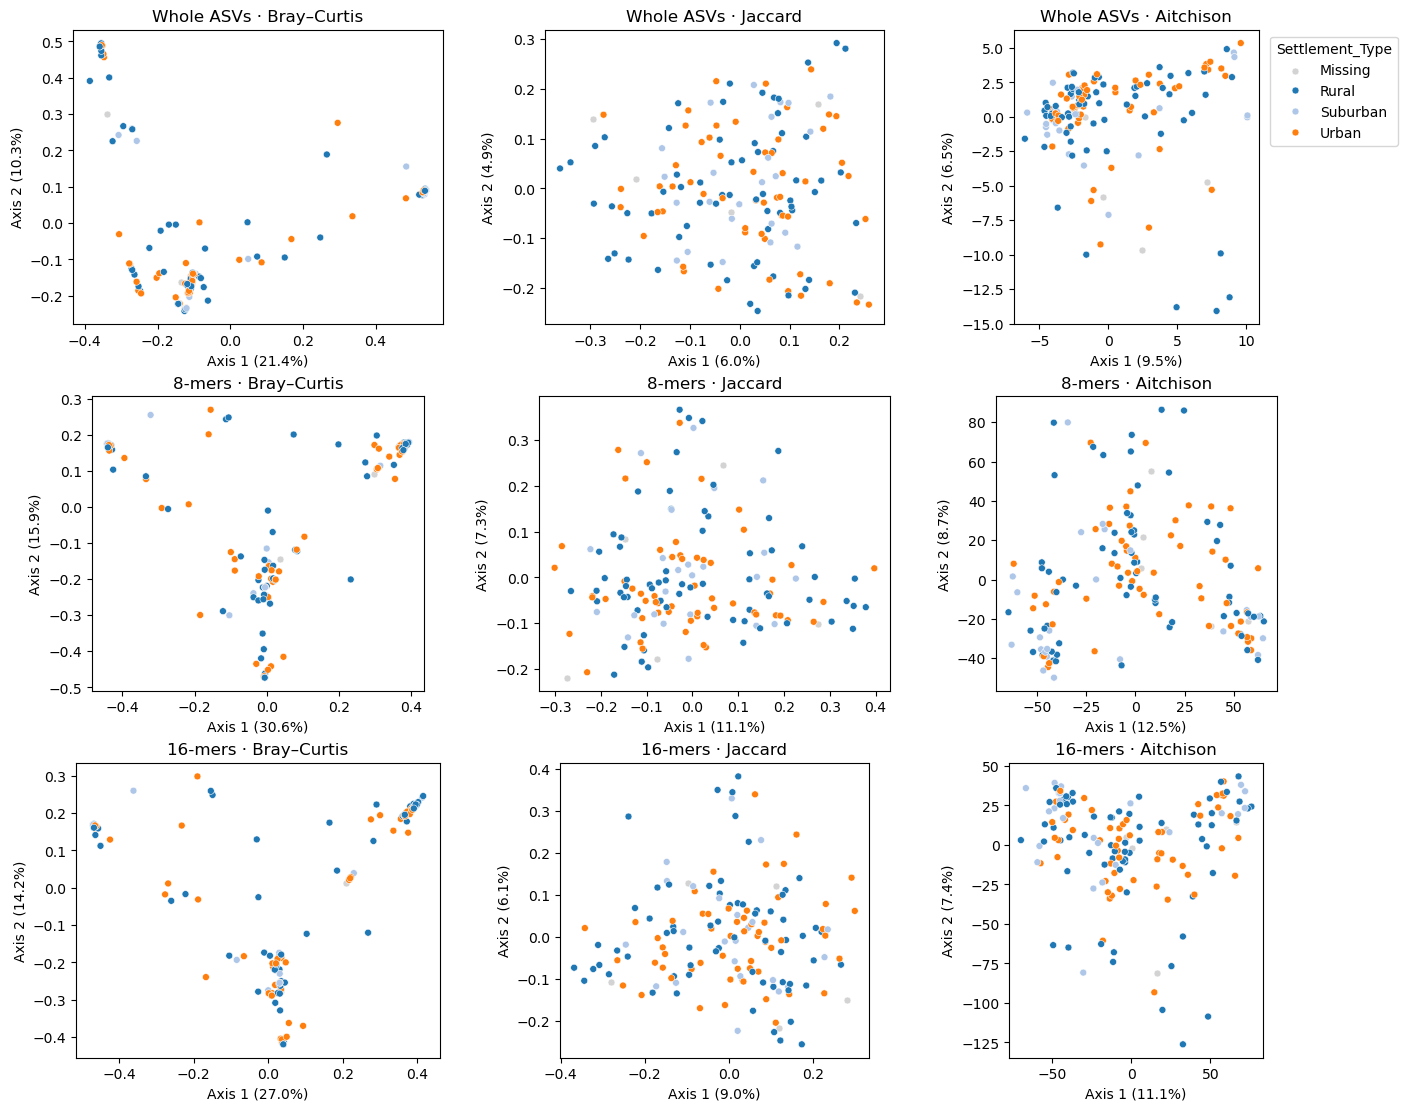

In [37]:
color_by = "Settlement_Type"  # Try "diet_type_sample" or "age_years_sample"

sample_values = metadata_df[color_by].reindex(sorted(expected_ids))
display(sample_values.value_counts(dropna=False))
is_numeric = pd.api.types.is_numeric_dtype(sample_values)

if is_numeric:
    color_options = {
        "palette": "viridis",
        "hue_norm": (sample_values.min(), sample_values.max()),
    }
else:
    color_options = {
        "palette": "tab20",
        "hue_order": sorted(sample_values.dropna().unique()),
    }

fig, axes = plt.subplots(3, 3, figsize=(14, 11), layout="constrained")

for row, paths in enumerate(pcoa_paths):
    for col, path in enumerate(paths):
        ax = axes[row, col]
        pcs = Artifact.load(path).view(OrdinationResults)

        pcs_data = pcs.samples.iloc[:, :2].copy()
        pcs_data.columns = ["Axis 1", "Axis 2"]
        pcs_data_with_md = pcs_data.join(sample_values, how="left")

        has_value = pcs_data_with_md[color_by].notna()
        show_legend = row == 0 and col == 2

        scatterplot(
            data=pcs_data_with_md.loc[~has_value],
            x="Axis 1", y="Axis 2", color="lightgray", s=25, ax=ax,
            label="Missing" if show_legend else None,
        )
        scatterplot(
            data=pcs_data_with_md.loc[has_value],
            x="Axis 1", y="Axis 2", hue=color_by, s=25, ax=ax,
            legend="brief" if show_legend else False,
            **color_options,
        )

        ax.set(
            title=f"{feature_labels[row]} · {metric_labels[col]}",
            xlabel=f"Axis 1 ({pcs.proportion_explained.iloc[0]:.1%})",
            ylabel=f"Axis 2 ({pcs.proportion_explained.iloc[1]:.1%})",
            aspect="equal",
        )

axes[0, 2].legend(title=color_by, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.savefig(vis_dir / f"pcoa_comparison_{color_by}.png", dpi=300)
plt.show()

Rural, suburban, and urban samples overlapped on the first two PCoA axes across all nine combinations. The 8-mer and 16-mer Bray–Curtis ordinations showed similar groupings of samples, with mixed settlement labels within those groupings. Overall, no clear separation by settlement type was visible on the first two PCoA axes across the nine method combinations.

### 2.2 - Diet type

diet_type_sample
Omnivore                            118
Vegetarian but eat seafood            8
Omnivore but do not eat red meat      8
Vegetarian                            6
Vegan                                 5
NaN                                   5
Name: count, dtype: int64

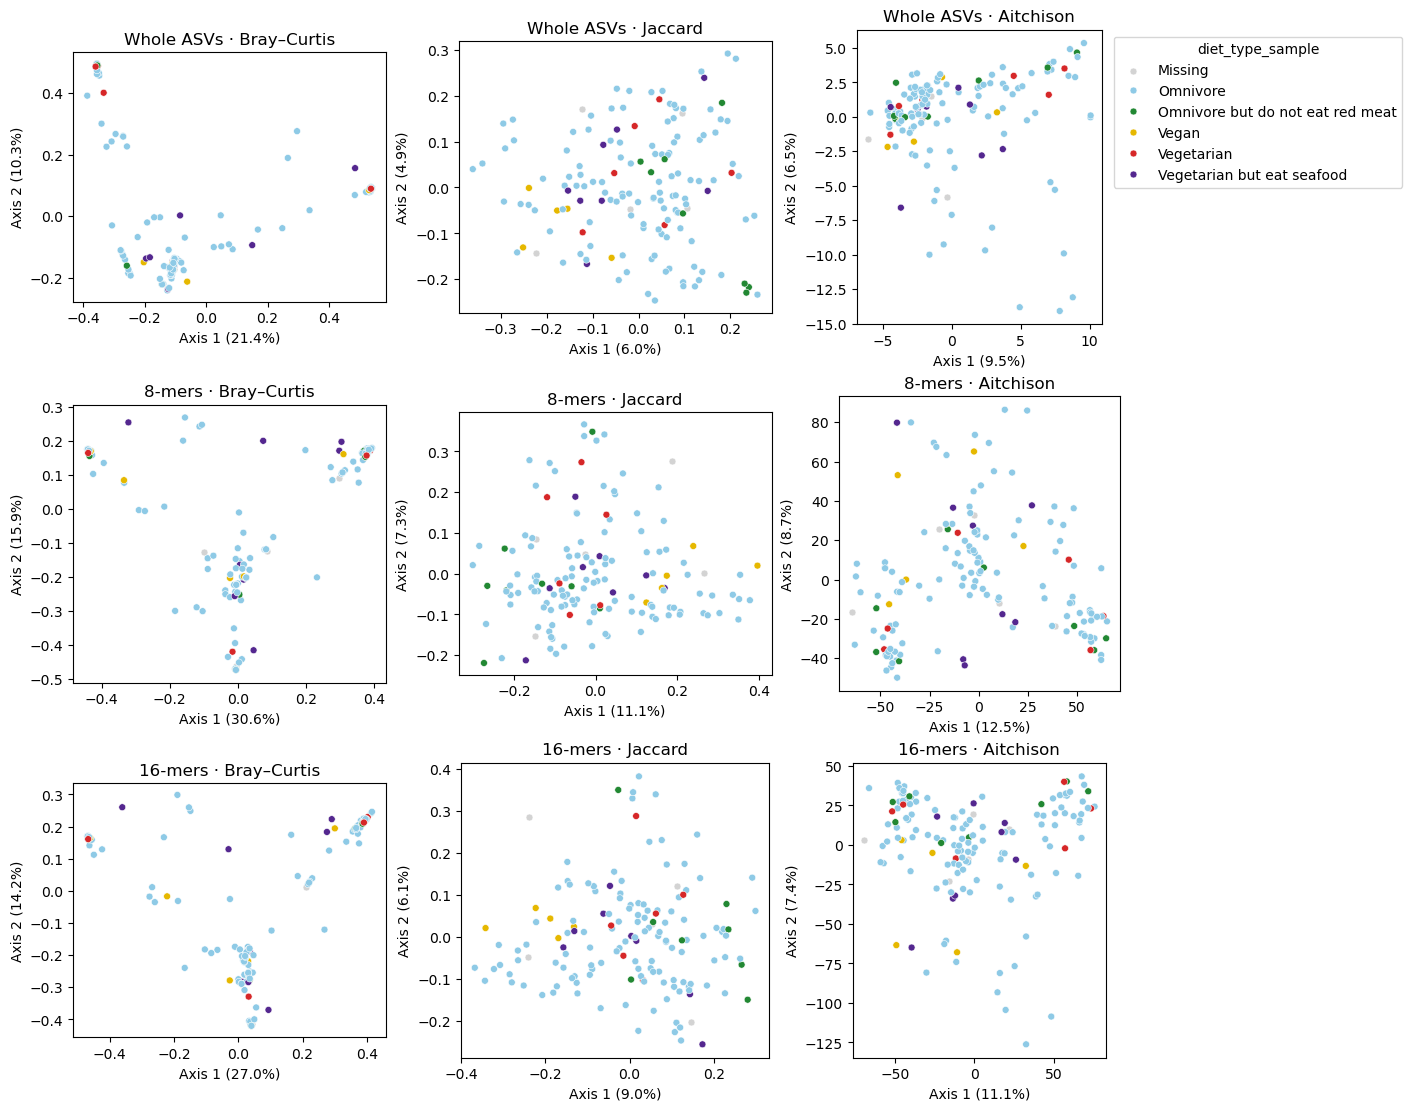

In [30]:
color_by = "diet_type_sample"  # Change to "Settlement_Type" or "age_years_sample" to switch views.

sample_values = metadata_df[color_by].reindex(sorted(expected_ids))
is_numeric = pd.api.types.is_numeric_dtype(sample_values)

if is_numeric:
    color_options = {
        "palette": "viridis",
        "hue_norm": (sample_values.min(), sample_values.max()),
    }
else:
    display(sample_values.value_counts(dropna=False))

    diet_palette = {
        "Omnivore": "#8ECAE6",                         # Light blue
        "Omnivore but do not eat red meat": "#228833", # Green
        "Vegan": "#E6B800",                           # Yellow
        "Vegetarian": "#D62728",                      # Red
        "Vegetarian but eat seafood": "#54278F",       # Dark purple
    }
    color_options = {
        "palette": diet_palette if color_by == "diet_type_sample" else "tab20",
        "hue_order": sorted(sample_values.dropna().unique()),
    }

fig, axes = plt.subplots(3, 3, figsize=(14, 11), layout="constrained")

for row, paths in enumerate(pcoa_paths):
    for col, path in enumerate(paths):
        ax = axes[row, col]
        pcs = Artifact.load(path).view(OrdinationResults)

        pcs_data = pcs.samples.iloc[:, :2].copy()
        pcs_data.columns = ["Axis 1", "Axis 2"]
        pcs_data_with_md = pcs_data.join(sample_values, how="left")

        has_value = pcs_data_with_md[color_by].notna()
        show_legend = row == 0 and col == 2

        scatterplot(
            data=pcs_data_with_md.loc[~has_value],
            x="Axis 1", y="Axis 2", color="lightgray", s=25, ax=ax,
            label="Missing" if show_legend else None,
        )
        scatterplot(
            data=pcs_data_with_md.loc[has_value],
            x="Axis 1", y="Axis 2", hue=color_by, s=25, ax=ax,
            legend="brief" if show_legend else False,
            **color_options,
        )

        ax.set(
            title=f"{feature_labels[row]} · {metric_labels[col]}",
            xlabel=f"Axis 1 ({pcs.proportion_explained.iloc[0]:.1%})",
            ylabel=f"Axis 2 ({pcs.proportion_explained.iloc[1]:.1%})",
            aspect="equal",
        )

axes[0, 2].legend(title=color_by, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.savefig(vis_dir / f"pcoa_comparison_{color_by}.png", dpi=300)
plt.show()

### 2.3 Age

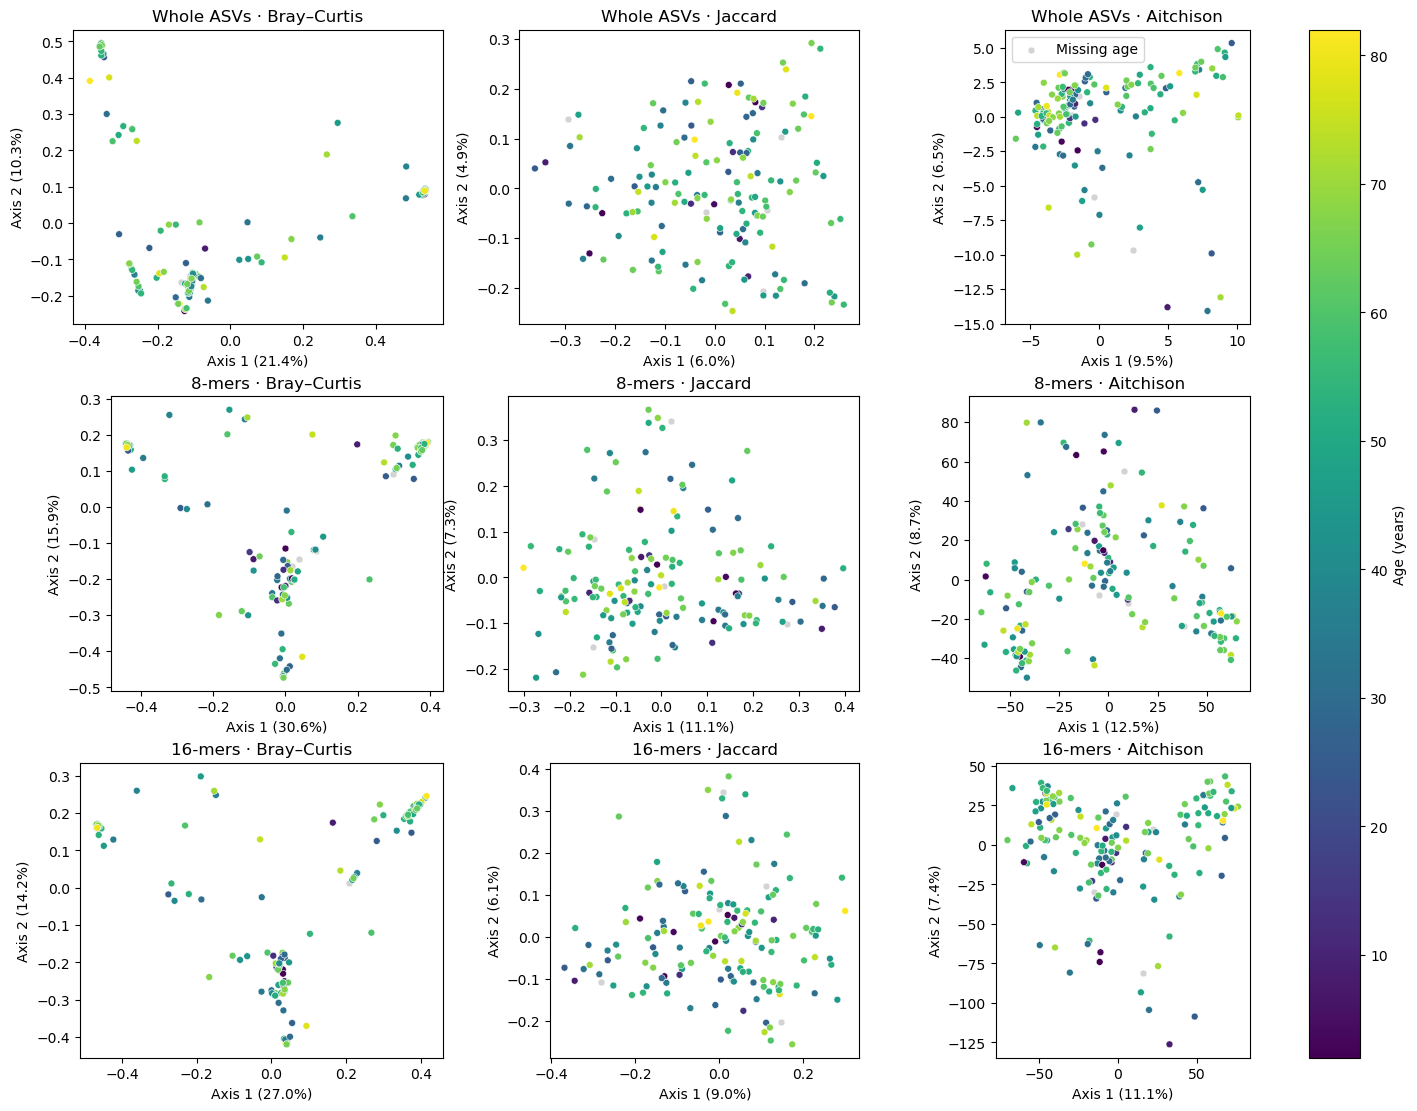

In [31]:
color_by = "age_years_sample"

sample_values = metadata_df[color_by].reindex(sorted(expected_ids))
age_norm = plt.Normalize(sample_values.min(), sample_values.max())

fig, axes = plt.subplots(3, 3, figsize=(14, 11), layout="constrained")

for row, paths in enumerate(pcoa_paths):
    for col, path in enumerate(paths):
        ax = axes[row, col]
        pcs = Artifact.load(path).view(OrdinationResults)

        pcs_data = pcs.samples.iloc[:, :2].copy()
        pcs_data.columns = ["Axis 1", "Axis 2"]
        pcs_data_with_md = pcs_data.join(sample_values, how="left")

        has_age = pcs_data_with_md[color_by].notna()

        scatterplot(
            data=pcs_data_with_md.loc[~has_age],
            x="Axis 1", y="Axis 2",
            color="lightgray", s=25, ax=ax,
            label="Missing age" if (row, col) == (0, 2) else None,
        )
        scatterplot(
            data=pcs_data_with_md.loc[has_age],
            x="Axis 1", y="Axis 2", hue=color_by,
            palette="viridis", hue_norm=age_norm,
            s=25, legend=False, ax=ax,
        )

        ax.set(
            title=f"{feature_labels[row]} · {metric_labels[col]}",
            xlabel=f"Axis 1 ({pcs.proportion_explained.iloc[0]:.1%})",
            ylabel=f"Axis 2 ({pcs.proportion_explained.iloc[1]:.1%})",
            aspect="equal",
        )

if sample_values.isna().any():
    axes[0, 2].legend(loc="best")

age_scale = plt.cm.ScalarMappable(norm=age_norm, cmap="viridis")
fig.colorbar(age_scale, ax=axes.ravel().tolist(), label="Age (years)")

fig.savefig(vis_dir / "pcoa_comparison_age_years_sample.png", dpi=300)
plt.show()

### 2.4 Sex

sex_sample
male      79
female    69
NaN        1
other      1
Name: count, dtype: int64

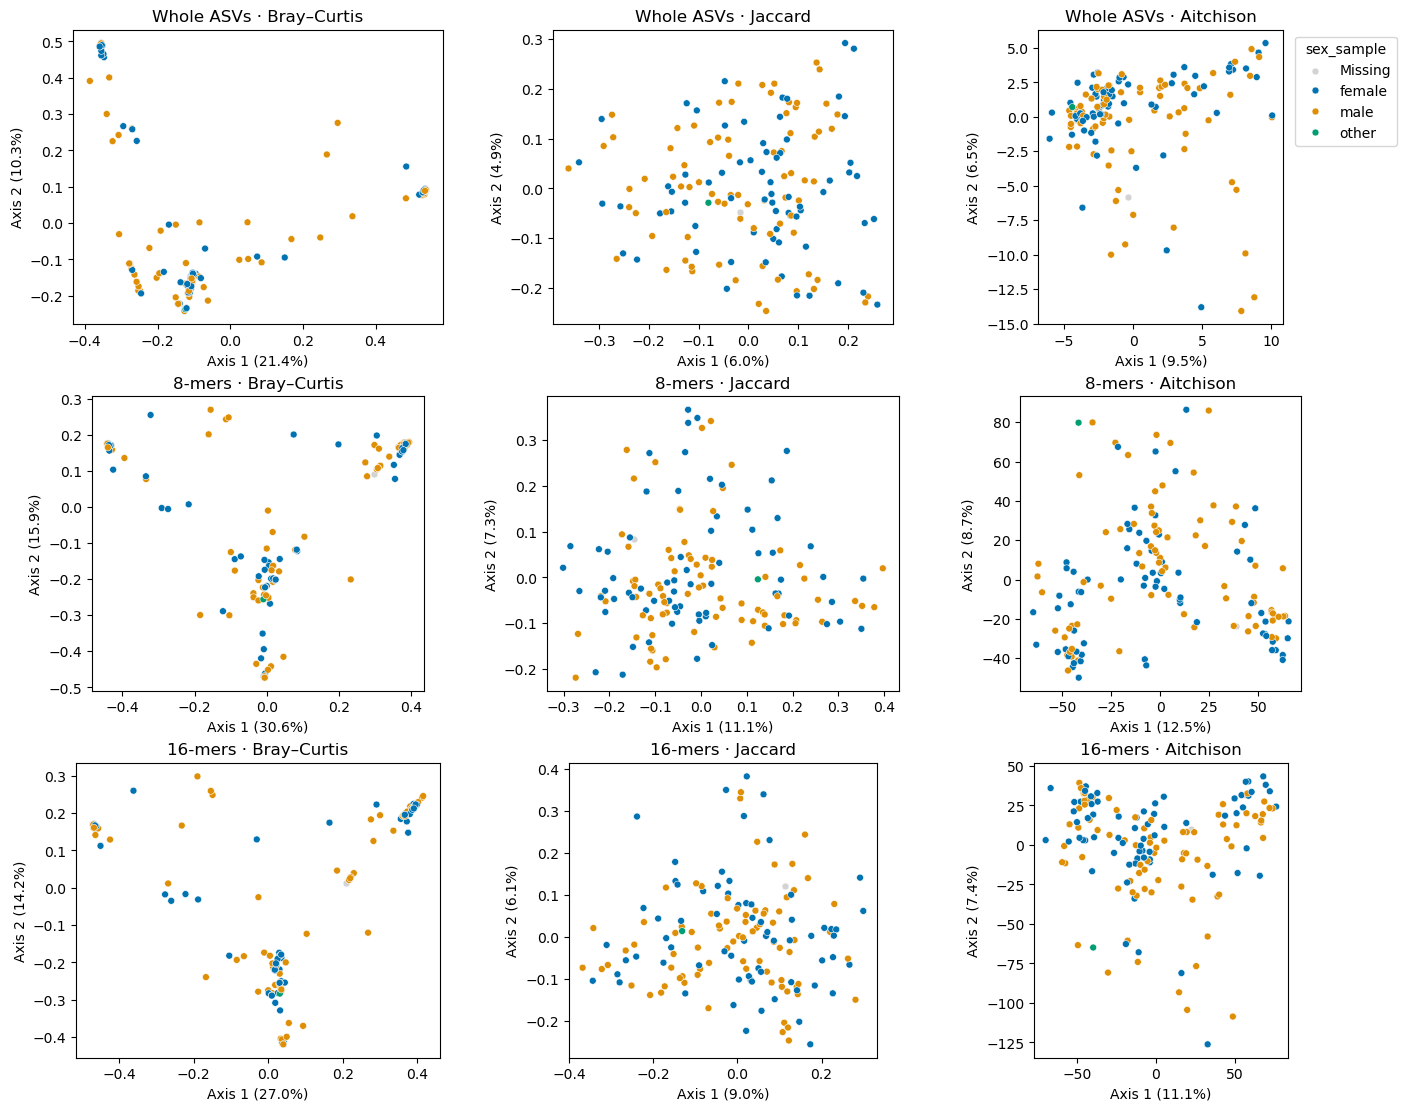

In [34]:
color_by = "sex_sample"

sample_values = metadata_df[color_by].reindex(sorted(expected_ids))
display(sample_values.value_counts(dropna=False))

categories = sorted(sample_values.dropna().unique())

fig, axes = plt.subplots(3, 3, figsize=(14, 11), layout="constrained")

for row, paths in enumerate(pcoa_paths):
    for col, path in enumerate(paths):
        ax = axes[row, col]
        pcs = Artifact.load(path).view(OrdinationResults)

        pcs_data = pcs.samples.iloc[:, :2].copy()
        pcs_data.columns = ["Axis 1", "Axis 2"]
        pcs_data_with_md = pcs_data.join(sample_values, how="left")

        has_value = pcs_data_with_md[color_by].notna()
        show_legend = row == 0 and col == 2

        scatterplot(
            data=pcs_data_with_md.loc[~has_value],
            x="Axis 1", y="Axis 2",
            color="lightgray", s=25, ax=ax,
            label="Missing" if show_legend else None,
        )
        scatterplot(
            data=pcs_data_with_md.loc[has_value],
            x="Axis 1", y="Axis 2", hue=color_by,
            hue_order=categories, palette="colorblind",
            s=25, legend="full" if show_legend else False, ax=ax,
        )

        ax.set(
            title=f"{feature_labels[row]} · {metric_labels[col]}",
            xlabel=f"Axis 1 ({pcs.proportion_explained.iloc[0]:.1%})",
            ylabel=f"Axis 2 ({pcs.proportion_explained.iloc[1]:.1%})",
            aspect="equal",
        )

axes[0, 2].legend(
    title=color_by, loc="upper left", bbox_to_anchor=(1.02, 1)
)

fig.savefig(vis_dir / f"pcoa_comparison_{color_by}.png", dpi=300)
plt.show()

## Summary and workflow selection

We compared whole-ASV, 8-mer, and 16-mer feature tables using Bray–Curtis, Jaccard, and Aitchison distances. All nine analyses used the same 150 samples from the ASV table rarefied to 16,000 reads per sample.<br>

The first two PCoA axes showed different structures across metrics. Jaccard produced relatively diffuse point clouds, while Bray–Curtis showed tighter groups, with similar broad patterns for 8-mers and 16-mers. Several Aitchison ordinations contained a denser central cloud and samples positioned farther away.<br>

Coloring the ordinations by settlement, diet, age, and sex revealed no clear group separation or age gradient on the first two axes. Associations with these variables remain to be assessed using the full distance matrices.<br>

For subsequent analyses, we select 16-mer Bray–Curtis as the primary workflow to examine differences in the abundance of shared ITS1 sequence segments. The comparison gave no clear visual reason to prefer 8-mers over 16-mers. We retain whole-ASV Bray–Curtis as a sensitivity check to assess whether conclusions depend on the feature representation.<br>

Settlement-colored Aitchison plots had been explored before this notebook. The metadata overlays presented here are exploratory, and their visual separation was not used as a criterion for selecting the primary workflow.